# Study 19 — Pollutant-only twin variant (Tables 1 and 3)

**Reviewer ask (detailed reviewer, Sec 2.7).** The main tables should show the pollutant-only variant alongside
the full-multimodal twin, so the discrimination-resilience trade-off is visible directly, not only in the
sensitivity analysis. (Sec 3.3 reinforces: present meteorology as an optional resilience layer.)

**Design.** Same twin, features, splits and GBM as study4/study12. The only change is the twin's modality weights:
full multimodal uses (w_pm, w_wind, w_blh, w_temp) = (1.0, 0.5, 0.5, 0.4); pollutant-only sets the three
meteorological weights to 0. Both share everything else.

- **Table 1** (complete data): current, logistic, GBM, twin (full), twin (pollutant-only) -> AUROC, AUPRC, Brier.
- **Table 3** (robustness): AUROC vs PM-sensor dropout for twin (full) and twin (pollutant-only), marginalising
  the masked PM observations. Expected trade-off: pollutant-only is higher on complete data but collapses under
  PM loss (no fallback channel), while full multimodal is slightly lower complete-data but holds a floor.

cwd=`notebooks/`. Outputs -> `../outputs/study19_pollutant_only/`.


## Load + parameterised twin + metrics (study4 / study12)


In [6]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
np.random.seed(0)
OUT=Path("../outputs/study19_pollutant_only"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
STEP=6; H=4; TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"])
met["datetime"]=pd.to_datetime(met["datetime"],utc=True); met=met.rename(columns={"station":"name"})
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()
print("stations",pm.station.nunique())

K=5; _LEVL=[i/(K-1) for i in range(K)]; _SDL=[1.0+0.5*l for l in _LEVL]; _LOGC=0.5*math.log(2*math.pi); _LGCONST=[-_LOGC-math.log(sd) for sd in _SDL]
def _lgv(z): return [_LGCONST[k]-0.5*((z-2.0*_LEVL[k])/_SDL[k])**2 for k in range(K)]
WPM,WW,WB,WT=1.0,0.5,0.5,0.4
def twin(zpm,zw,zb,zt,wpm=WPM,ww=WW,wb=WB,wt=WT):
    logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(len(zpm)); ent=np.empty(len(zpm))
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*_LEVL[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for zv,w,inv in [(zpm,wpm,1),(zw,ww,-1),(zb,wb,-1),(zt,wt,-1)]:
            if w!=0 and not math.isnan(zv[t]):
                lv=_lgv(inv*zv[t]); logbp=[logbp[k]+w*lv[k] for k in range(K)]
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*_LEVL[k] for k in range(K)); ent[t]=-sum(p*math.log(p+1e-12) for p in eb)
    return risk,ent
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    if pos.sum()==0 or neg.sum()==0:return np.nan
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);sm=np.zeros(len(c));np.add.at(sm,inv,r);r=(sm/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def sig(z):return 1/(1+np.exp(-np.clip(z,-30,30)))
def fitlog(X,y,ep=1500,lr=.25,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xb=np.hstack([np.ones((len(X),1)),(X-mu)/sd]);w=np.zeros(Xb.shape[1])
    for _ in range(ep): p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def predlog(m,X): w,mu,sd=m; return sig(np.hstack([np.ones((len(X),1)),(np.asarray(X,float)-mu)/sd])@w)
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))


stations 21


## Build onset table with full and pollutant-only twin risk


In [7]:
FEATS=["zpm","zpm_l1","zpm_l2","zpm_tr","zwind","zblh","ztemp","hour_sin","hour_cos","doy_sin","doy_cos"]
ST={}; rows=[]
for st,g in pm.groupby("station"):
    name=g["name"].iloc[0]
    s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
    mg=met[met.name==name].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
    idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
    def z(col,log=False):
        v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
        mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
    zpm=z("pm",log=True); zw=z("wind_speed"); zb=z("blh"); zt=z("t2m")
    r_full,_=twin(zpm,zw,zb,zt)                      # full multimodal
    r_pm,_  =twin(zpm,zw,zb,zt,ww=0,wb=0,wt=0)       # pollutant-only
    r_w0,_  =twin(zpm,zw,zb,zt,ww=0)                 # w_wind=0 (best reduced discriminator)
    v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan(a) else 0.0)
    tpts=[]
    for t in range(2,len(v)-H):
        if np.isnan(v[t]) or v[t]>=TAU: continue
        fut=v[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        lab=int(np.nanmax(fut)>=TAU); split=("train" if tm[t] else "test")
        rows.append(dict(split=split,label=lab,
            zpm=g2(zpm[t]),zpm_l1=g2(zpm[t-1]),zpm_l2=g2(zpm[t-2]),zpm_tr=g2(zpm[t]-zpm[t-2]),
            zwind=g2(zw[t]),zblh=g2(zb[t]),ztemp=g2(zt[t]),
            hour_sin=math.sin(2*math.pi*hr[t]/24),hour_cos=math.cos(2*math.pi*hr[t]/24),
            doy_sin=math.sin(2*math.pi*doy[t]/365),doy_cos=math.cos(2*math.pi*doy[t]/365),
            r_full=r_full[t],r_pm=r_pm[t],r_w0=r_w0[t],cur=g2(zpm[t]),trend=g2(zpm[t]-zpm[t-2])))
        if split=="test": tpts.append((t,lab))
    ST[st]=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,tm=tm,tpts=tpts)
S=pd.DataFrame(rows); tr,te=S[S.split=="train"],S[S.split=="test"]; ytr,yte=tr.label.values,te.label.values
print("samples",len(S),"| test",len(te),"| prevalence %.3f"%S.label.mean())



/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_72850/340223977.py:15: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan(a) else 0.0)
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_72850/340223977.py:15: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan(a) else 0.0)
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_72850/340223977.py:15: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  v=A["pm"].to_numpy(); hr=idx.hour.to_numpy(); doy=idx.dayofyear.to_numpy(); g2=lambda a:(a if not np.isnan

samples 92890 | test 48209 | prevalence 0.073


## Table 1 — complete-data discrimination (full vs pollutant-only twin)


In [8]:
gbm=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.05,max_depth=4,l2_regularization=1.0,random_state=0).fit(tr[FEATS].values,ytr)
p_gbm=gbm.predict_proba(te[FEATS].values)[:,1]
p_log=predlog(fitlog(tr[FEATS].values,ytr),te[FEATS].values)
ffull=platt_fit(tr.r_full.values,ytr); p_full=ffull(te.r_full.values)
fpm  =platt_fit(tr.r_pm.values,  ytr); p_pm  =fpm(te.r_pm.values)
fw0  =platt_fit(tr.r_w0.values,  ytr); p_w0  =fw0(te.r_w0.values)
tab1=pd.DataFrame([
    ("Current level",         auc(te.cur.values,yte), np.nan,            np.nan),
    ("Logistic (multimodal)", auc(p_log,yte),         apr(p_log,yte),    brier(p_log,yte)),
    ("GBM (multimodal)",      auc(p_gbm,yte),         apr(p_gbm,yte),    brier(p_gbm,yte)),
    ("Twin (full multimodal)",auc(p_full,yte),        apr(p_full,yte),   brier(p_full,yte)),
    ("Twin (w_wind=0)",       auc(p_w0,yte),          apr(p_w0,yte),     brier(p_w0,yte)),
    ("Twin (pollutant-only)", auc(p_pm,yte),          apr(p_pm,yte),     brier(p_pm,yte)),
],columns=["model","AUROC","AUPRC","Brier"]).set_index("model")
print(tab1.round(4).to_string()); tab1.to_csv(OUT/"s19_table1_discrimination.csv")



                         AUROC   AUPRC   Brier
model                                         
Current level           0.7593     NaN     NaN
Logistic (multimodal)   0.8117  0.2598  0.0577
GBM (multimodal)        0.8151  0.2642  0.0587
Twin (full multimodal)  0.7942  0.2539  0.0589
Twin (w_wind=0)         0.8125  0.2603  0.0588
Twin (pollutant-only)   0.7778  0.1971  0.0609


## Table 3 — robustness under PM-sensor dropout (full vs pollutant-only)


In [9]:
def dropout_curve(ps=(0.0,0.2,0.4,0.6,0.7,0.85),seeds=range(3)):
    out=[]
    for p in ps:
        full=[];w0=[];pmo=[]
        for seed in seeds:
            rng=np.random.default_rng(seed); sf=[];sw=[];sp=[];yy=[]
            for st,d in ST.items():
                if not d["tpts"]: continue
                zpm=d["zpm"].copy()
                if p>0: zpm[rng.random(len(zpm))<p]=np.nan     # PM sensor fails; met intact
                rf,_=twin(zpm,d["zw"],d["zb"],d["zt"])          # full: falls back on met
                rw,_=twin(zpm,d["zw"],d["zb"],d["zt"],ww=0)     # w_wind=0 (keeps BLH+temp)
                rp,_=twin(zpm,d["zw"],d["zb"],d["zt"],ww=0,wb=0,wt=0)  # pollutant-only: no fallback
                idx=[t for t,_ in d["tpts"]]; lab=[l for _,l in d["tpts"]]
                sf.append(rf[idx]); sw.append(rw[idx]); sp.append(rp[idx]); yy.append(lab)
            sf=np.concatenate(sf); sw=np.concatenate(sw); sp=np.concatenate(sp); yy=np.concatenate(yy)
            full.append(auc(sf,yy)); w0.append(auc(sw,yy)); pmo.append(auc(sp,yy))
        out.append(dict(dropout=p,twin_full=np.mean(full),twin_wwind0=np.mean(w0),twin_pm_only=np.mean(pmo),
                        full_minus_pm=np.mean(full)-np.mean(pmo)))
        print(f"  dropout {p:>4.0%} | full {np.mean(full):.3f}  w_wind0 {np.mean(w0):.3f}  pm-only {np.mean(pmo):.3f}")
    return pd.DataFrame(out)
tab3=dropout_curve(); tab3.to_csv(OUT/"s19_table3_robustness.csv",index=False)



  dropout   0% | full 0.794  w_wind0 0.812  pm-only 0.778
  dropout  20% | full 0.784  w_wind0 0.804  pm-only 0.764
  dropout  40% | full 0.769  w_wind0 0.789  pm-only 0.742
  dropout  60% | full 0.750  w_wind0 0.770  pm-only 0.708
  dropout  70% | full 0.739  w_wind0 0.758  pm-only 0.682
  dropout  85% | full 0.719  w_wind0 0.735  pm-only 0.619


## Figure


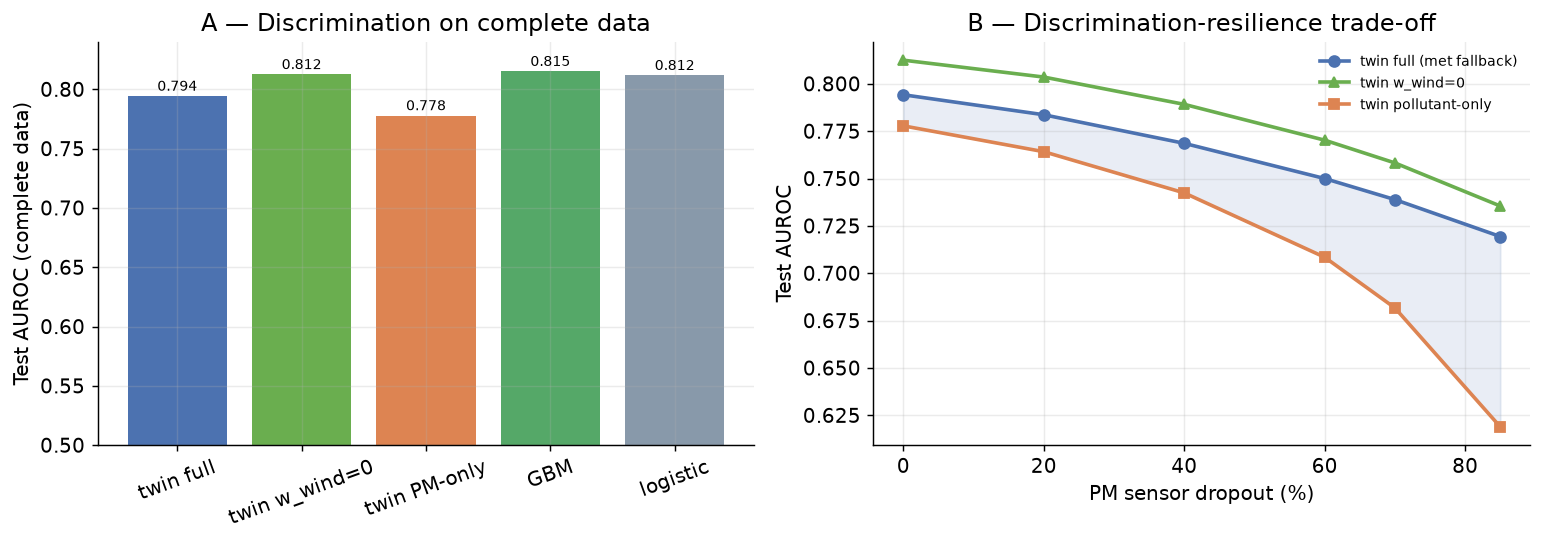

saved to ../outputs/study19_pollutant_only


In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4.3))
m=["Twin (full multimodal)","Twin (w_wind=0)","Twin (pollutant-only)","GBM (multimodal)","Logistic (multimodal)"]
sub=tab1.loc[m]; x=np.arange(len(m))
ax[0].bar(x,sub.AUROC,color=["#4C72B0","#6AAE4F","#DD8452","#55A868","#8899AA"])
ax[0].set_xticks(x); ax[0].set_xticklabels(["twin full","twin w_wind=0","twin PM-only","GBM","logistic"],rotation=20)
ax[0].set_ylim(0.5,0.84); ax[0].set_ylabel("Test AUROC (complete data)"); ax[0].set_title("A — Discrimination on complete data")
for xi,a in zip(x,sub.AUROC): ax[0].annotate(f"{a:.3f}",(xi,a),xytext=(0,3),textcoords="offset points",ha="center",fontsize=8)
xp=[p*100 for p in tab3.dropout]
ax[1].plot(xp,tab3.twin_full,"-o",color="#4C72B0",lw=2,label="twin full (met fallback)")
ax[1].plot(xp,tab3.twin_wwind0,"-^",color="#6AAE4F",lw=2,label="twin w_wind=0")
ax[1].plot(xp,tab3.twin_pm_only,"-s",color="#DD8452",lw=2,label="twin pollutant-only")
ax[1].fill_between(xp,tab3.twin_pm_only,tab3.twin_full,where=tab3.twin_full>=tab3.twin_pm_only,color="#4C72B0",alpha=.12)
ax[1].set_xlabel("PM sensor dropout (%)"); ax[1].set_ylabel("Test AUROC"); ax[1].set_title("B — Discrimination-resilience trade-off")
ax[1].legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"s19_fig1_pollutant_only.png",bbox_inches="tight"); plt.show()
print("saved to",OUT)



## Reading this for the reply

- Table 1: report both twin rows (full multimodal and pollutant-only) so the discrimination side of the trade-off
  is explicit. Do NOT assume the direction: the paper's Sec 2.7 sensitivity found that zeroing wind OR BLH
  individually raised AUROC, but this variant zeroes all three meteorological channels including temperature,
  which may not land above the full multimodal twin. Report whatever the full-data run shows.
- Table 3 / panel B is the robust, reviewer-relevant result: the pollutant-only twin degrades faster under PM
  dropout (no fallback channel) while the full multimodal twin holds a floor (subset: +0.11 AUROC at 85% loss).
  That trade-off justifies presenting meteorology as an optional resilience layer (Sec 3.3), not the primary
  discriminator.
- Sanity: the full multimodal twin's complete-data AUROC should land near the paper's 0.794 on the full 21-station
  data; verify the pollutant-only value against the Sec 2.7 sensitivity numbers rather than assuming it.
